<a href="https://colab.research.google.com/github/Gagandeep1227/ML-2/blob/main/SOM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install minisom numpy pandas matplotlib scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for minisom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=228107f434761728ef96c142e4636b593b38ffb6d4967d2b0ff9b474e3264b25
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom


Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

SOM Training Completed Successfully!


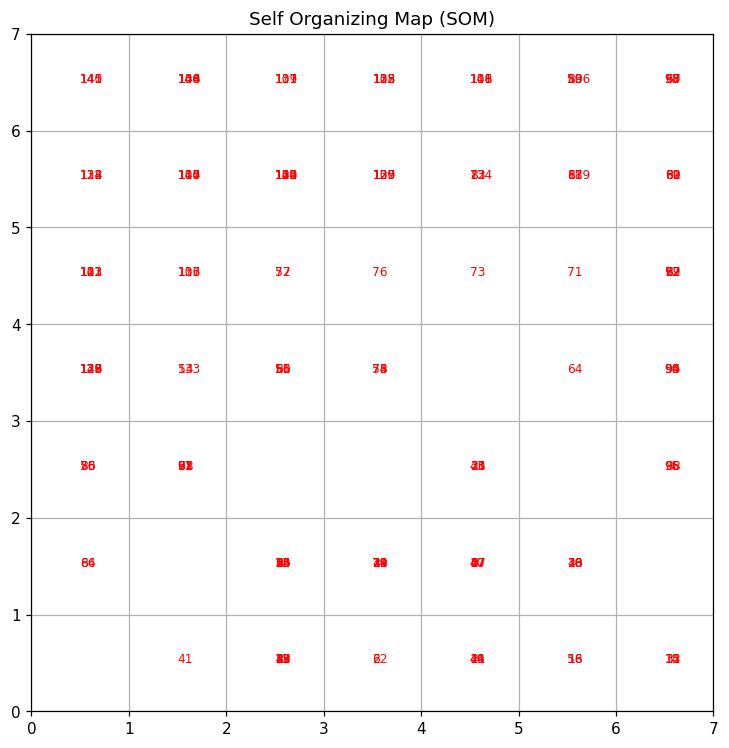

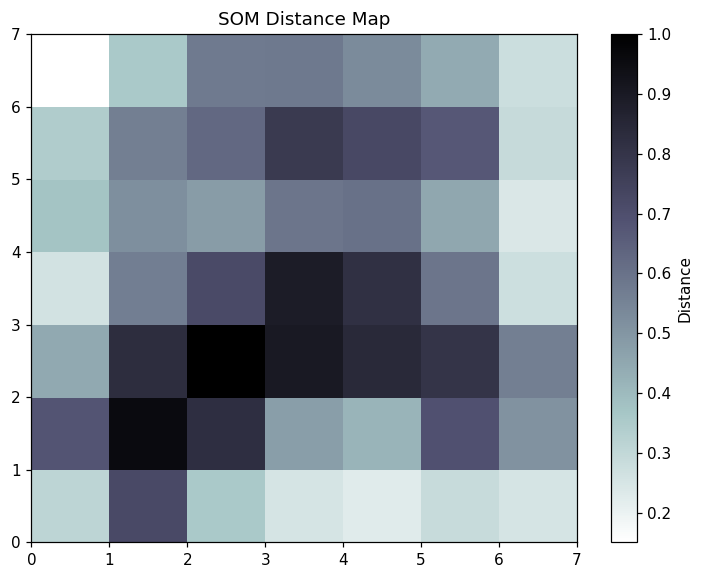

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print("Dataset:")
print(df.head())

scaler = MinMaxScaler()
data = scaler.fit_transform(df)

som = MiniSom(
    x=7,
    y=7,
    input_len=data.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

som.random_weights_init(data)

som.train_random(data, num_iteration=1000)

print("\nSOM Training Completed Successfully!")

plt.figure(figsize=(8, 8))

for i, x in enumerate(data):
    w = som.winner(x)

    plt.text(
        w[0] + 0.5,
        w[1] + 0.5,
        str(i),
        color='red',
        fontsize=8
    )

plt.title("Self Organizing Map (SOM)")
plt.xlim([0, 7])
plt.ylim([0, 7])
plt.grid()
plt.show()

plt.figure(figsize=(8, 6))

plt.pcolor(
    som.distance_map().T,
    cmap='bone_r'
)

plt.colorbar(label="Distance")

plt.title("SOM Distance Map")
plt.show()

In [9]:
pip install numpy pandas matplotlib scikit-learn minisom

Loading dataset...


/tmp/ipykernel_550/365498054.py:15: DtypeWarning: Columns (2,5,6,9,16,17,20,24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/creditcard.csv", on_bad_lines='skip')



Dataset Loaded Successfully!
Dataset Shape: (541688, 31)

First 5 Rows:
   Time        V1                   V2        V3        V4  \
0   0.0 -1.359807  -0.0727811733098497  2.536347  1.378155   
1   0.0  1.191857     0.26615071205963  0.166480  0.448154   
2   1.0 -1.358354    -1.34016307473609  1.773209  0.379780   
3   1.0 -0.966272   -0.185226008082898  1.792993 -0.863291   
4   2.0 -1.158233    0.877736754848451  1.548718  0.403034   

                    V5        V6        V7        V8        V9  ...       V21  \
0   -0.338320769942518  0.462388  0.239599  0.098698  0.363787  ... -0.018307   
1   0.0600176492822243 -0.082361 -0.078803  0.085102 -0.255425  ... -0.225775   
2   -0.503198133318193  1.800499  0.791461  0.247676 -1.514654  ...  0.247998   
3  -0.0103088796030823  1.247203  0.237609  0.377436 -1.387024  ... -0.108300   
4   -0.407193377311653  0.095921  0.592941 -0.270533  0.817739  ... -0.009431   

        V22       V23       V24       V25       V26       V27      

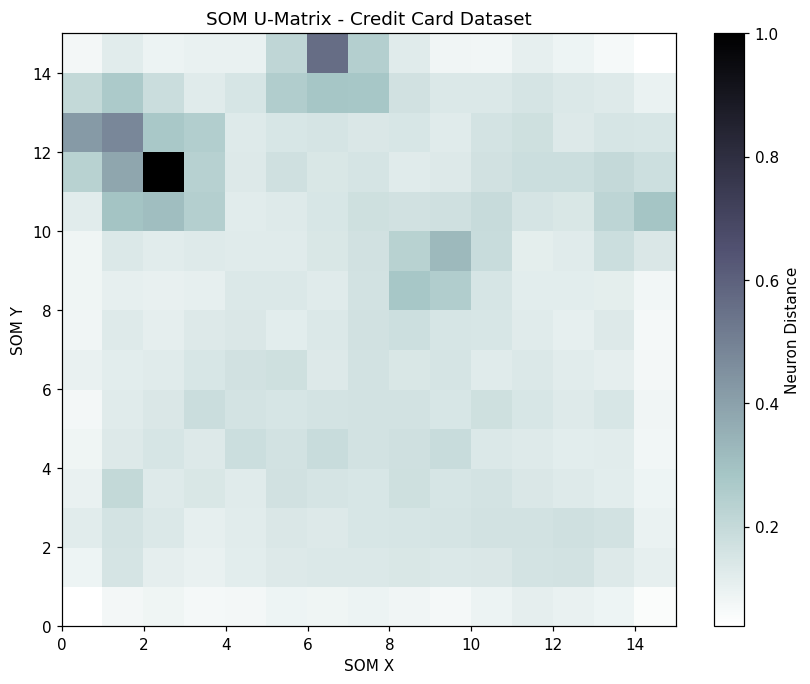

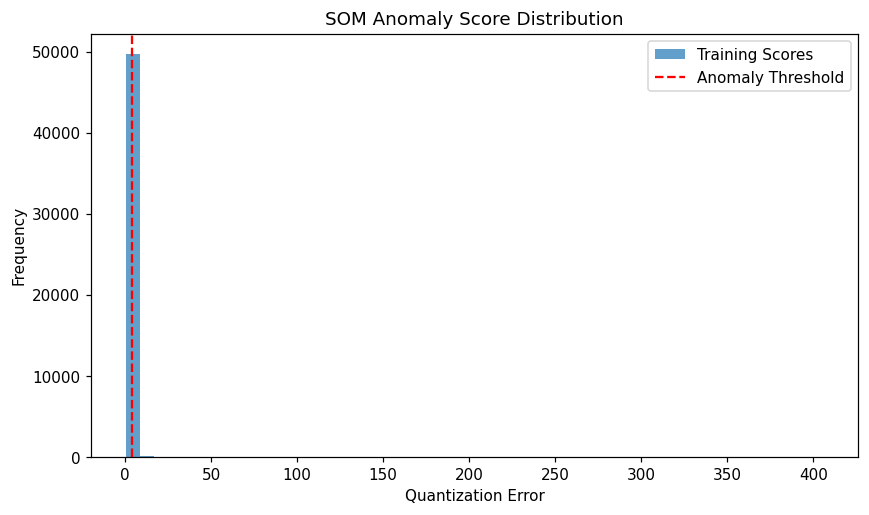


Sample Results:
   Actual_Class  Anomaly_Score  Predicted_Anomaly
0             0       2.033400              False
1             0       2.096348              False
2             0       1.164098              False
3             0       2.477237              False
4             0       2.012825              False
5             0       2.587183              False
6             0       3.683385              False
7             0       1.918510              False
8             0       1.247978              False
9             0       1.380262              False

Results saved to som_results.csv

PROGRAM EXECUTED SUCCESSFULLY!


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from minisom import MiniSom
from sklearn.preprocessing import StandardScaler

print("Loading dataset...")

df = pd.read_csv("/content/creditcard.csv", on_bad_lines='skip')

print("\nDataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

X = df.drop(columns=["Class"])

y = df["Class"]

X = X.apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

y = pd.to_numeric(y, errors='coerce').fillna(0).astype(int)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rng = np.random.default_rng(42)

train_size = min(50000, len(X_scaled))
train_indices = rng.choice(
    len(X_scaled),
    size=train_size,
    replace=False
)

X_train = X_scaled[train_indices]

print("\nTraining samples:", len(X_train))

som = MiniSom(
    x=15,
    y=15,
    input_len=X_train.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

som.random_weights_init(X_train)

print("\nTraining SOM...")

som.train_random(
    X_train,
    num_iteration=5000,
    verbose=True
)

print("\nSOM Training Completed!")

train_quantized = som.quantization(X_train)

train_scores = np.linalg.norm(
    X_train - train_quantized,
    axis=1
)

threshold = np.percentile(train_scores, 95)

eval_size = min(10000, len(X_scaled))

eval_indices = rng.choice(
    len(X_scaled),
    size=eval_size,
    replace=False
)

X_eval = X_scaled[eval_indices]
y_eval = y.iloc[eval_indices].to_numpy()

eval_quantized = som.quantization(X_eval)

anomaly_scores = np.linalg.norm(
    X_eval - eval_quantized,
    axis=1
)

predictions = anomaly_scores > threshold

print("\nAnomaly Detection Results")
print("Threshold:", round(threshold, 4))
print("Transactions Evaluated:", eval_size)
print("Unusual Transactions:", predictions.sum())

actual_fraud = y_eval == 1

print("\nActual Fraud Transactions:", actual_fraud.sum())

if actual_fraud.sum() > 0:
    detected_fraud = np.sum(predictions & actual_fraud)

    print("Fraud Transactions Flagged:", detected_fraud)

plt.figure(figsize=(9, 7))

plt.pcolor(
    som.distance_map().T,
    cmap="bone_r"
)

plt.colorbar(label="Neuron Distance")
plt.title("SOM U-Matrix - Credit Card Dataset")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")

plt.show()

plt.figure(figsize=(9, 5))

plt.hist(
    train_scores,
    bins=50,
    alpha=0.7,
    label="Training Scores"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label="Anomaly Threshold"
)

plt.title("SOM Anomaly Score Distribution")
plt.xlabel("Quantization Error")
plt.ylabel("Frequency")
plt.legend()

plt.show()

results = pd.DataFrame({
    "Actual_Class": y_eval,
    "Anomaly_Score": anomaly_scores,
    "Predicted_Anomaly": predictions
})

print("\nSample Results:")
print(results.head(10))

results.to_csv("som_results.csv", index=False)

print("\nResults saved to som_results.csv")
print("\nPROGRAM EXECUTED SUCCESSFULLY!")
